Crank Nicoloson Formula

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
D = 4 # Diffusivity
time_step = 0.25
step_size = 0.25
length = 1 

In [3]:
r = (D * time_step) / (2 * step_size**2)
r

8.0

In [4]:
r

8.0

In [5]:
x_range = np.arange(0, length + step_size, step_size)
t_range = np.arange(0, length + time_step, time_step)

In [6]:
x_len, t_len = len(x_range), len(t_range)

A matrix
\\
-r, (1 + 2r), -r

In [7]:
first_diag = np.array([-r] * (x_len - 1))
first_diag.T


array([-8., -8., -8., -8.])

In [8]:
second_diag = np.array([2*r + 1] * x_len)
second_diag.T

array([17., 17., 17., 17., 17.])

In [9]:
A = np.diag(second_diag, k = 0) + np.diag(first_diag, k = -1) + np.diag(first_diag, k = 1)
A

array([[17., -8.,  0.,  0.,  0.],
       [-8., 17., -8.,  0.,  0.],
       [ 0., -8., 17., -8.,  0.],
       [ 0.,  0., -8., 17., -8.],
       [ 0.,  0.,  0., -8., 17.]])

The B matrix is just the A matrix times -1

In [10]:
otherFirst_diag = np.array([r] * (x_len - 1))
otherSecond_diag = np.array([-2*r + 1] * x_len)

In [11]:
B = np.diag(otherSecond_diag, k = 0) + np.diag(otherFirst_diag, k = -1) + np.diag(otherFirst_diag, k = 1)
B

array([[-15.,   8.,   0.,   0.,   0.],
       [  8., -15.,   8.,   0.,   0.],
       [  0.,   8., -15.,   8.,   0.],
       [  0.,   0.,   8., -15.,   8.],
       [  0.,   0.,   0.,   8., -15.]])

In [12]:
#B_inverse = np.linalg.inv(B)
#B_inverse

In [13]:
n = 1

In [14]:
grid = np.zeros((x_len, t_len))
grid[:,0] = np.sin(n * np.pi * x_range)
grid[0, :] = 0
grid[-1, :] = 0
grid

array([[0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.70710678, 0.        , 0.        , 0.        , 0.        ],
       [1.        , 0.        , 0.        , 0.        , 0.        ],
       [0.70710678, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ]])

In [15]:
grid[1:-1, 0]

array([0.70710678, 1.        , 0.70710678])

In [16]:
A[1:-1, 1:-1]

array([[17., -8.,  0.],
       [-8., 17., -8.],
       [ 0., -8., 17.]])

In [17]:
for i in range(0, t_len - 1):
    x_n = grid[1:-1, i]
    #x_n = grid[:,i]
    
    #multiple = #B_inverse @ A
    b_bar = np.dot(B[1:-1, 1:-1], x_n)
    x_new = np.linalg.solve(A[1:-1, 1:-1], b_bar)
    grid[:, i + 1] = x_new

ValueError: could not broadcast input array from shape (3,) into shape (5,)

In [ ]:
grid

array([[10.        , -8.07383617,  6.81938732, -5.89275094,  5.15409349],
       [ 0.70710678,  0.88599136, -1.53323612,  1.79749161, -1.89395095],
       [ 1.        ,  0.28239302, -0.62483714,  0.64305269, -0.55874424],
       [ 0.70710678,  0.17488025, -0.32592748,  0.25658933, -0.14173771],
       [ 0.        ,  0.41505272, -0.43730404,  0.35322679, -0.25762287]])

In [ ]:
matrix = np.zeros((x_len, t_len))

for j in range(t_len):
    for i in range(x_len):
        matrix[i, j] = np.sin(n * x_range[i] * np.pi) * np.exp(-np.pi**2 * D * t_range[j] * (n**2))

np.array(matrix.round(7))

array([[0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00],
       [7.071068e-01, 3.660000e-05, 0.000000e+00, 0.000000e+00,
        0.000000e+00],
       [1.000000e+00, 5.170000e-05, 0.000000e+00, 0.000000e+00,
        0.000000e+00],
       [7.071068e-01, 3.660000e-05, 0.000000e+00, 0.000000e+00,
        0.000000e+00],
       [0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00]])

In [ ]:
frob_norm = np.linalg.norm(grid - matrix, 'fro')
frob_norm

np.float64(1.1852199582523366)

In [ ]:
frob_norm / (grid.shape[0] * grid.shape[1])

np.float64(0.04740879833009346)

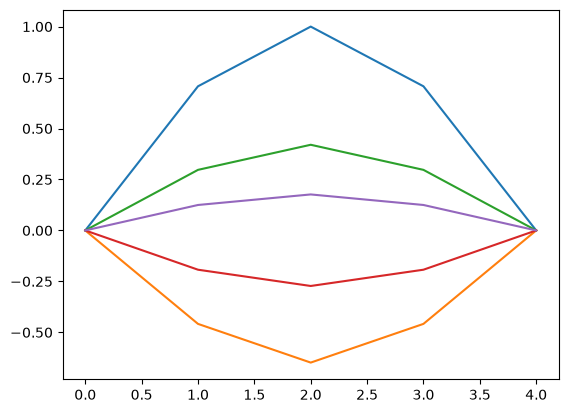

In [ ]:
plt.plot(grid)

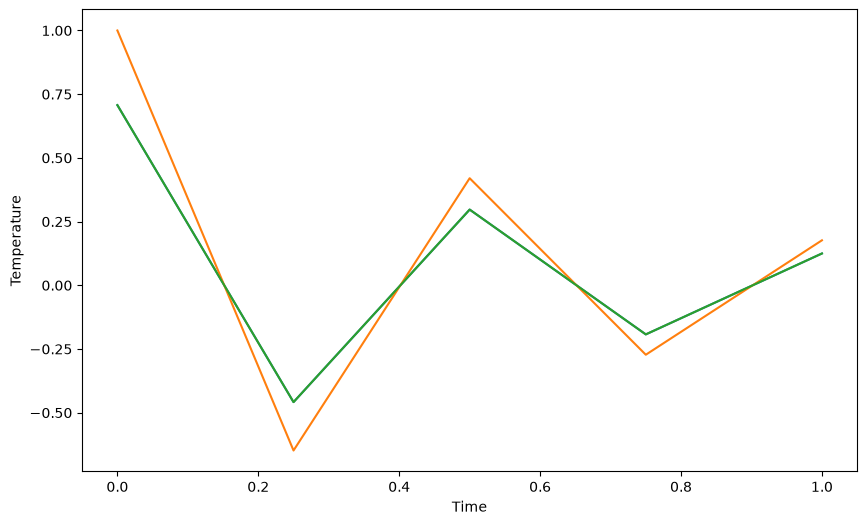

In [ ]:
plt.figure(figsize=(10, 6))
for i in range(1, x_len - 1):
    plt.plot(t_range, grid[i, :], linewidth=1.5)
    #plt.plot(t_range, grid[2, :], linewidth = 1.5)
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.show()

Log Plot

/var/folders/53/csg89y6d4b1bm1tt092_y8q40000gn/T/ipykernel_52991/3111996833.py:3: RuntimeWarning: invalid value encountered in log
  plt.plot(t_range, np.log(grid[1, :]), linewidth=1.5)


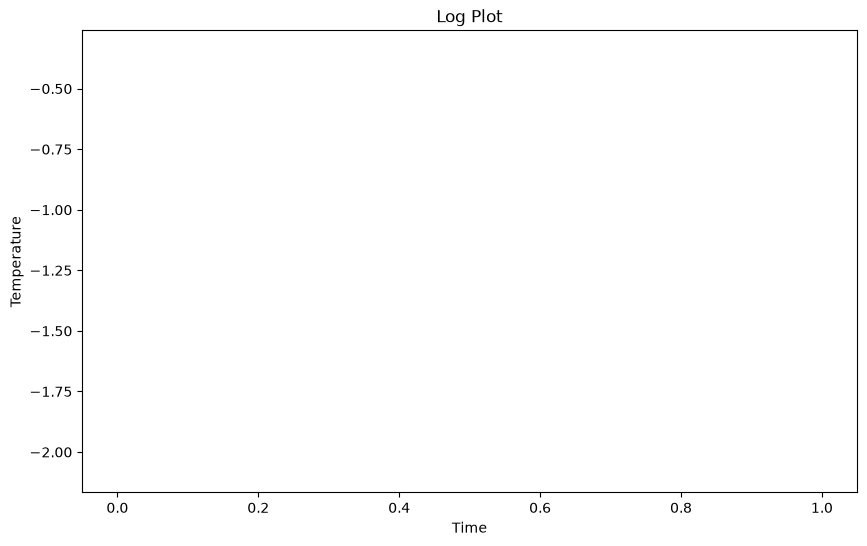

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(t_range, np.log(grid[1, :]), linewidth=1.5)

plt.xlabel("Time")
plt.ylabel("Temperature")
plt.title("Log Plot")
plt.show()

Find the slope of the line

In [ ]:
slope, intercept = np.polyfit(t_range, np.log(grid[1,:]), 1)
slope


/var/folders/53/csg89y6d4b1bm1tt092_y8q40000gn/T/ipykernel_52991/824836817.py:1: RuntimeWarning: invalid value encountered in log
  slope, intercept = np.polyfit(t_range, np.log(grid[1,:]), 1)


np.float64(nan)

Slope on the plot is actually

In [ ]:
-1 * (np.pi**2) * (D)

-39.47841760435743